# 01 — Exploratory data analysis: IEEE-CIS Fraud Detection

**Stage L02** of the PFA project (data ingestion and exploratory analysis).
Goal: understand the data well enough to design features (L03), the time split and evaluation (L04),
and to avoid leakage. Findings are summarised in `docs/eda_findings.md`.

Data: `data/processed/train.parquet` (labelled, 590,540 transactions) built by `ml/scripts/make_parquet.py`.
The Kaggle test file (no labels) is used only where noted (time coverage, drift).

Figures are saved to `reports/figures/eda/`.

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from fraudml import config
from fraudml.data.ingest import load_split, memory_mb

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", context="notebook")

FIG_DIR = config.FIGURES_DIR / "eda"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save_fig(fig, name):
    """Save a figure for the report/slides (PNG, moderate DPI) and show it."""
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}.png", dpi=110)
    plt.show()


t0 = time.perf_counter()
df = load_split("train")
load_s = time.perf_counter() - t0
TARGET = config.TARGET
OVERALL_RATE = df[TARGET].mean()
print(f"Loaded train in {load_s:.1f} s")

Loaded train in 0.7 s


## 1. Size, memory and column groups

In [2]:
print(f"rows: {len(df):,}   columns: {df.shape[1]}   memory: {memory_mb(df):,.0f} MB")
display(df.dtypes.astype(str).value_counts().rename("n_columns").to_frame())


def column_group(col):
    for prefix in ("id_", "C", "D", "M", "V"):
        if col.startswith(prefix) and col[len(prefix) :].isdigit():
            return f"{prefix}*"
    for prefix in ("card", "addr", "dist"):
        if col.startswith(prefix):
            return prefix
    return col


groups = pd.Series({c: column_group(c) for c in df.columns}, name="group")
group_sizes = groups.value_counts()
display(group_sizes[group_sizes > 1].rename("n_columns").to_frame())
print("Single columns:", ", ".join(group_sizes[group_sizes == 1].index))

rows: 590,540   columns: 435   memory: 931 MB


,n_columns
float32,398
category,31
int32,2
int8,1
datetime64[us],1
float64,1
int16,1


,n_columns
group,
V*,339
id_*,38
D*,15
C*,14
M*,9
card,6
addr,2
dist,2


Single columns: TransactionID, isFraud, TransactionDT, TransactionDatetime, TransactionAmt, ProductCD, P_emaildomain, R_emaildomain, DeviceType, DeviceInfo


**Column groups (from the competition description):**
`card1–6` card details (card4 = network, card6 = debit/credit) · `addr1–2` billing region / country ·
`dist1–2` distances · `P_/R_emaildomain` payer / recipient e-mail domain ·
`C1–14` counts (e.g. how many addresses are linked to the card; exact meaning masked) ·
`D1–15` time deltas (e.g. days since previous transaction) · `M1–9` match flags (e.g. name on card vs address) ·
`V1–339` features engineered by Vesta (masked) · `id_01–38`, `DeviceType`, `DeviceInfo` identity / device data.

**Observations (section 1)**
- 590,540 transactions × 435 columns (931 MB in memory after downcasting, loads in about 1 s).
- About **415 of the 434 raw features are masked or semi-masked** (`V`, `id_`, `C`, `D`, `M`). Only about 20
  columns are directly readable. → Explanations for analysts will rely heavily on **engineered features**
  built from readable columns (L03), with masked feature groups summarised in one line each.

## 2. Target: how rare is fraud?

In [3]:
counts = df[TARGET].value_counts().rename(index={0: "legit", 1: "fraud"})
amount_by_class = df.groupby(TARGET)["TransactionAmt"].sum().rename(index={0: "legit", 1: "fraud"})
summary = pd.DataFrame(
    {
        "transactions": counts,
        "share_of_transactions": counts / counts.sum(),
        "total_amount_usd": amount_by_class,
        "share_of_amount": amount_by_class / amount_by_class.sum(),
    }
)
display(
    summary.style.format(
        {
            "transactions": "{:,}",
            "share_of_transactions": "{:.2%}",
            "total_amount_usd": "{:,.0f}",
            "share_of_amount": "{:.2%}",
        }
    )
)
print(
    f"Imbalance ratio: 1 fraud for every {counts['legit'] / counts['fraud']:.1f} legit transactions"
)

,transactions,share_of_transactions,total_amount_usd,share_of_amount
isFraud,,,,
legit,"569,877",96.50%,"76,655,104",96.13%
fraud,"20,663",3.50%,"3,083,845",3.87%


Imbalance ratio: 1 fraud for every 27.6 legit transactions


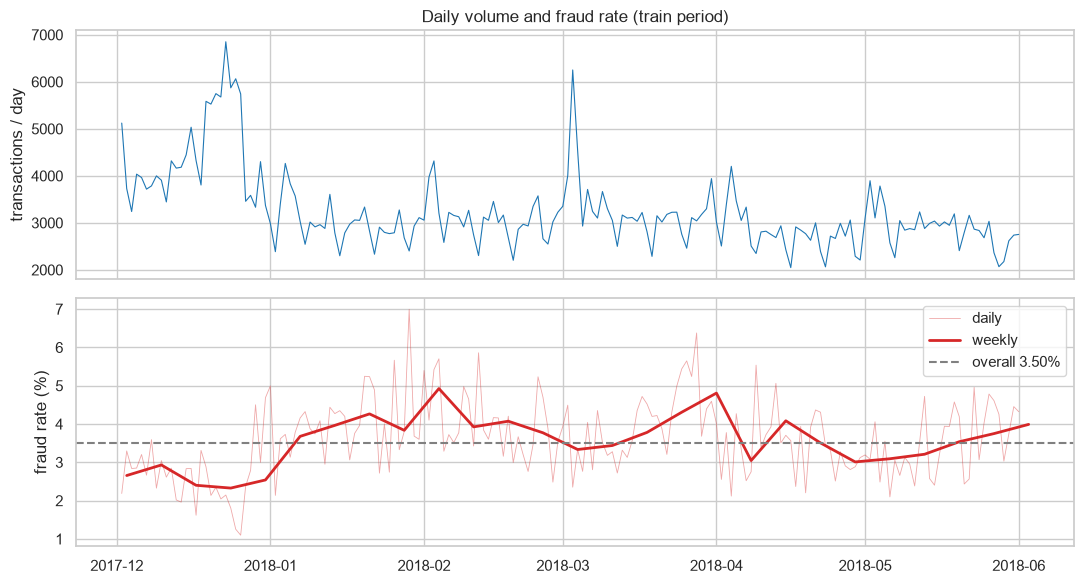

Transactions per day: median 3,050 (min 2,048, max 6,852)
Weekly fraud rate: min 2.33%, max 4.93%
Frauds per day: median 113


In [4]:
daily = df.set_index(config.DATETIME_COL)[TARGET].resample("D").agg(["size", "mean"])
weekly = df.set_index(config.DATETIME_COL)[TARGET].resample("W").agg(["size", "mean"])

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(daily.index, daily["size"], lw=0.8, color="tab:blue")
axes[0].set_ylabel("transactions / day")
axes[0].set_title("Daily volume and fraud rate (train period)")
axes[1].plot(daily.index, daily["mean"] * 100, lw=0.6, color="tab:red", alpha=0.4, label="daily")
axes[1].plot(weekly.index, weekly["mean"] * 100, lw=2, color="tab:red", label="weekly")
axes[1].axhline(OVERALL_RATE * 100, ls="--", color="grey", label=f"overall {OVERALL_RATE:.2%}")
axes[1].set_ylabel("fraud rate (%)")
axes[1].legend(loc="upper right")
save_fig(fig, "02_volume_and_fraud_rate_over_time")

print(
    f"Transactions per day: median {daily['size'].median():,.0f} "
    f"(min {daily['size'].min():,}, max {daily['size'].max():,})"
)
print(f"Weekly fraud rate: min {weekly['mean'].min():.2%}, max {weekly['mean'].max():.2%}")
print(f"Frauds per day: median {(daily['size'] * daily['mean']).median():.0f}")

**Observations (section 2)**
- **3.50% fraud** (20,663 of 590,540), i.e. 1 fraud for every 27.6 legit transactions. Fraud is 3.87% of the
  money ($3.08 M of $79.7 M), so fraud transactions are slightly larger on average.
- About **3,050 transactions and 113 frauds per day** (median). The assumed review capacity of 150 cases/day
  (project assumption) is about 4.9% of daily volume, close to the fraud rate, so the capacity is realistic.
- Volume has a **December holiday peak** (up to 6,852/day around Christmas), a one-day spike in early March,
  and a weekly cycle.
- The **fraud rate is not stable over time**: about 2.3–2.9% per week in December, then 3–4.9% from January.
  → Metrics will differ between time periods, which is one more reason for a time-based split (L03/L04)
  and per-week stability reporting. A threshold tuned on one period may need checking on the next.

## 3. Missing values

In [5]:
missing = df.isna().mean()
by_group = (
    pd.DataFrame({"group": groups, "missing": missing})
    .groupby("group")["missing"]
    .agg(n_columns="size", mean_missing="mean", min_missing="min", max_missing="max")
    .sort_values("mean_missing", ascending=False)
)
display(
    by_group.style.format({c: "{:.1%}" for c in ["mean_missing", "min_missing", "max_missing"]})
)

print(f"Columns with no missing values: {(missing == 0).sum()}")
print(f"Columns > 50% missing: {(missing > 0.5).sum()}   > 90% missing: {(missing > 0.9).sum()}")

,n_columns,mean_missing,min_missing,max_missing
group,,,,
id_*,38,84.8%,75.6%,99.2%
DeviceInfo,1,79.9%,79.9%,79.9%
R_emaildomain,1,76.8%,76.8%,76.8%
dist,2,76.6%,59.7%,93.6%
DeviceType,1,76.2%,76.2%,76.2%
D*,15,58.2%,0.2%,93.4%
M*,9,49.9%,28.7%,59.3%
V*,339,43.0%,0.0%,86.1%
P_emaildomain,1,16.0%,16.0%,16.0%


Columns with no missing values: 21
Columns > 50% missing: 214   > 90% missing: 12


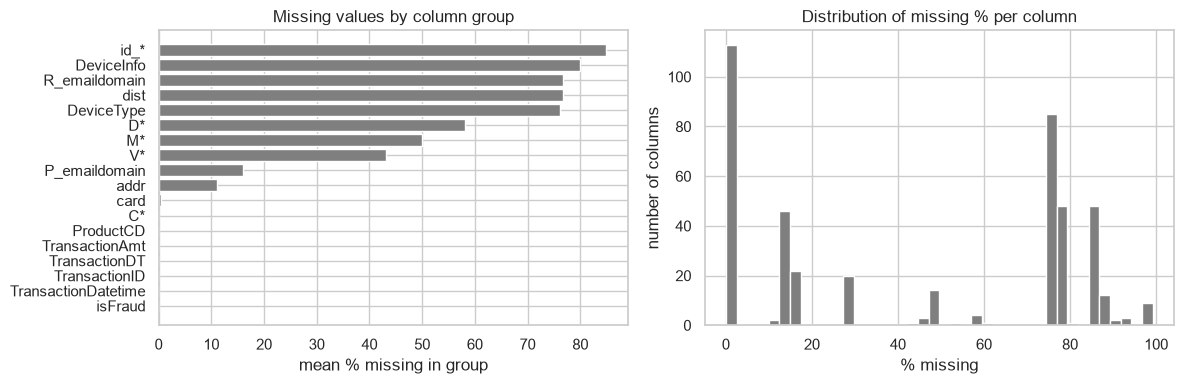

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
order = by_group.index
axes[0].barh(order, by_group["mean_missing"] * 100, color="tab:gray")
axes[0].invert_yaxis()
axes[0].set_xlabel("mean % missing in group")
axes[0].set_title("Missing values by column group")
axes[1].hist(missing * 100, bins=40, color="tab:gray")
axes[1].set_xlabel("% missing")
axes[1].set_ylabel("number of columns")
axes[1].set_title("Distribution of missing % per column")
save_fig(fig, "03_missing_values")

Is "missingness" itself informative? Two quick checks: transactions **with vs without identity data**,
and the fraud rate when a few common columns are missing vs present.

In [7]:
has_identity = df["id_01"].notna()
ident_tab = df.groupby(has_identity)[TARGET].agg(transactions="size", fraud_rate="mean")
ident_tab.index = ident_tab.index.map({False: "no identity record", True: "has identity record"})
display(ident_tab.style.format({"transactions": "{:,}", "fraud_rate": "{:.2%}"}))

rows = []
for col in ["addr1", "dist1", "P_emaildomain", "R_emaildomain", "D1", "D2", "M4", "DeviceInfo"]:
    is_na = df[col].isna()
    rows.append(
        {
            "column": col,
            "missing_share": is_na.mean(),
            "fraud_rate_if_missing": df.loc[is_na, TARGET].mean(),
            "fraud_rate_if_present": df.loc[~is_na, TARGET].mean(),
        }
    )
display(pd.DataFrame(rows).set_index("column").style.format("{:.2%}"))

,transactions,fraud_rate
id_01,,
no identity record,"446,307",2.09%
has identity record,"144,233",7.85%


,missing_share,fraud_rate_if_missing,fraud_rate_if_present
column,,,
addr1,11.13%,11.78%,2.46%
dist1,59.65%,4.52%,2.00%
P_emaildomain,15.99%,2.95%,3.60%
R_emaildomain,76.75%,2.08%,8.18%
D1,0.21%,3.62%,3.50%
D2,47.55%,4.56%,2.54%
M4,47.66%,1.86%,4.99%
DeviceInfo,79.91%,2.55%,7.25%


**Observations (section 3)**
- Missing values are everywhere: **214 of 434 columns are more than 50% missing**, 12 are more than 90% missing.
  Only 21 columns are complete.
- Identity data exists for only **24.4%** of transactions, but those transactions are **3.8× riskier**
  (7.85% vs 2.09% fraud).
- **Missingness carries signal.** Missing `addr1` → 11.8% fraud vs 2.5%; *present* `R_emaildomain` → 8.2% vs 2.1%;
  present `DeviceInfo` → 7.3% vs 2.6%.
- → For L03/L04: **keep NaN as NaN** (LightGBM/XGBoost handle missing values natively and learn from them)
  rather than mean-imputing. Add explicit flags for the most informative ones (e.g. `has_identity`,
  `addr1_missing`), which also give clear plain-language risk factors.

## 4. Readable features vs fraud

These are the features an analyst can understand, so they matter most for explainable risk factors.
For categorical columns we show volume and fraud rate per category (categories with very few
transactions are grouped as "other" to avoid noisy rates).

In [8]:
def rate_table(col, min_count=1000, top=None, data=df):
    s = data[col].astype("object").fillna("(missing)")
    tab = data.groupby(s, observed=True)[TARGET].agg(transactions="size", fraud_rate="mean")
    small = tab["transactions"] < min_count
    if small.any():
        other = data.loc[s.isin(tab.index[small]), TARGET]
        tab = tab[~small]
        tab.loc["other (small)"] = [len(other), other.mean()]
    tab["share"] = tab["transactions"] / len(data)
    tab = tab.sort_values("transactions", ascending=False)
    if top:
        tab = tab.head(top)
    return tab[["transactions", "share", "fraud_rate"]]


def plot_rates(tab, title, ax):
    colors = ["tab:red" if r > OVERALL_RATE else "tab:blue" for r in tab["fraud_rate"]]
    ax.barh(tab.index.astype(str), tab["fraud_rate"] * 100, color=colors)
    ax.axvline(OVERALL_RATE * 100, ls="--", color="grey")
    ax.invert_yaxis()
    ax.set_xlabel("fraud rate (%)")
    ax.set_title(title)


FMT = {"transactions": "{:,.0f}", "share": "{:.1%}", "fraud_rate": "{:.2%}"}

### 4.1 Transaction amount

,count,mean,std,min,25%,50%,75%,99%,max
legit,"569,877.00",134.51,239.40,0.25,43.97,68.50,120.00,"1,104.00","31,937.39"
fraud,"20,663.00",149.24,232.21,0.29,35.04,75.00,161.00,994.00,"5,191.00"


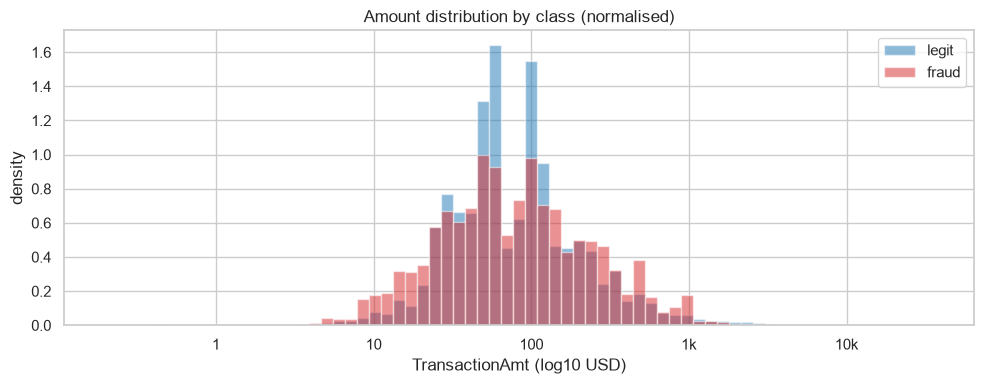

Whole-dollar amounts: 51.8% of transactions; fraud rate 3.59% vs 3.41% for non-round amounts


In [9]:
amt = df.groupby(TARGET)["TransactionAmt"].describe(percentiles=[0.25, 0.5, 0.75, 0.99])
amt.index = ["legit", "fraud"]
display(amt.style.format("{:,.2f}"))

fig, ax = plt.subplots(figsize=(10, 4))
bins = np.linspace(np.log10(0.2), np.log10(35000), 70)
for label, color in [(0, "tab:blue"), (1, "tab:red")]:
    vals = np.log10(df.loc[df[TARGET] == label, "TransactionAmt"])
    ax.hist(
        vals, bins=bins, density=True, alpha=0.5, color=color, label="fraud" if label else "legit"
    )
ax.set_xlabel("TransactionAmt (log10 USD)")
ax.set_ylabel("density")
ax.set_xticks(np.log10([1, 10, 100, 1000, 10000]), ["1", "10", "100", "1k", "10k"])
ax.legend()
ax.set_title("Amount distribution by class (normalised)")
save_fig(fig, "04_amount_by_class")

cents = (df["TransactionAmt"] * 100).round() % 100
round_amount = cents == 0
print(
    f"Whole-dollar amounts: {round_amount.mean():.1%} of transactions; "
    f"fraud rate {df.loc[round_amount, TARGET].mean():.2%} vs "
    f"{df.loc[~round_amount, TARGET].mean():.2%} for non-round amounts"
)

### 4.2 Product, card network, card type

ProductCD


,transactions,share,fraud_rate
ProductCD,,,
W,"439,670",74.5%,2.04%
C,"68,519",11.6%,11.69%
R,"37,699",6.4%,3.78%
H,"33,024",5.6%,4.77%
S,"11,628",2.0%,5.90%


card4 (network)


,transactions,share,fraud_rate
card4,,,
visa,"384,767",65.2%,3.48%
mastercard,"189,217",32.0%,3.43%
american express,"8,328",1.4%,2.87%
discover,"6,651",1.1%,7.73%
(missing),"1,577",0.3%,2.60%


card6 (type)


,transactions,share,fraud_rate
card6,,,
debit,"439,938",74.5%,2.43%
credit,"148,986",25.2%,6.68%
(missing),"1,571",0.3%,2.48%
other (small),45,0.0%,0.00%


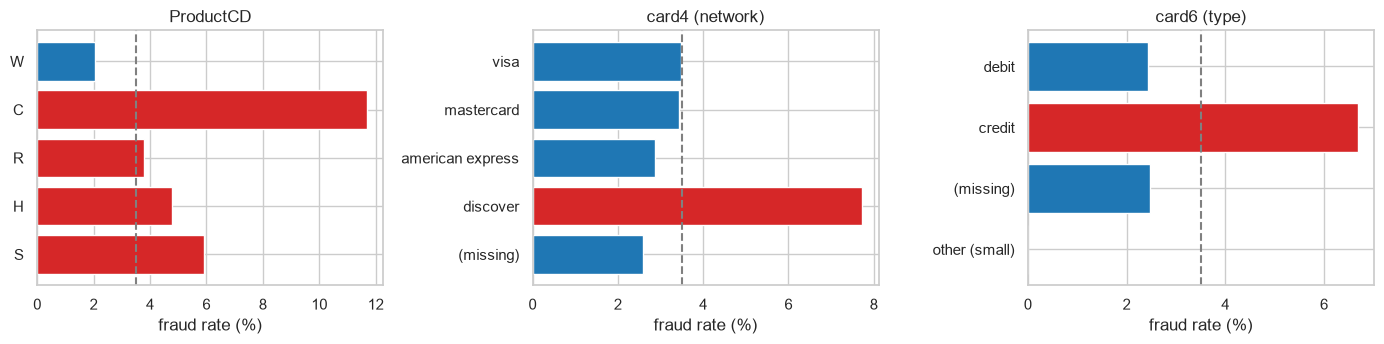

In [10]:
tabs = {
    "ProductCD": rate_table("ProductCD", min_count=1),
    "card4 (network)": rate_table("card4", min_count=1),
    "card6 (type)": rate_table("card6", min_count=1000),
}
for name, tab in tabs.items():
    print(name)
    display(tab.style.format(FMT))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, (name, tab) in zip(axes, tabs.items(), strict=True):
    plot_rates(tab, name, ax)
save_fig(fig, "04_product_card_rates")

### 4.3 E-mail domains

Payer e-mail domain (top by volume)


,transactions,share,fraud_rate
P_emaildomain,,,
gmail.com,"228,355",38.7%,4.35%
yahoo.com,"100,934",17.1%,2.28%
(missing),"94,456",16.0%,2.95%
hotmail.com,"45,250",7.7%,5.30%
anonymous.com,"36,998",6.3%,2.32%
aol.com,"28,289",4.8%,2.18%
other (small),"17,770",3.0%,3.08%
comcast.net,"7,888",1.3%,3.12%
icloud.com,"6,267",1.1%,3.14%


Recipient e-mail domain (top by volume)


,transactions,share,fraud_rate
R_emaildomain,,,
(missing),"453,249",76.8%,2.08%
gmail.com,"57,147",9.7%,11.92%
hotmail.com,"27,509",4.7%,7.78%
anonymous.com,"20,529",3.5%,2.91%
other (small),"14,056",2.4%,3.74%
yahoo.com,"11,842",2.0%,5.15%
aol.com,"3,701",0.6%,3.49%
outlook.com,"2,507",0.4%,16.51%


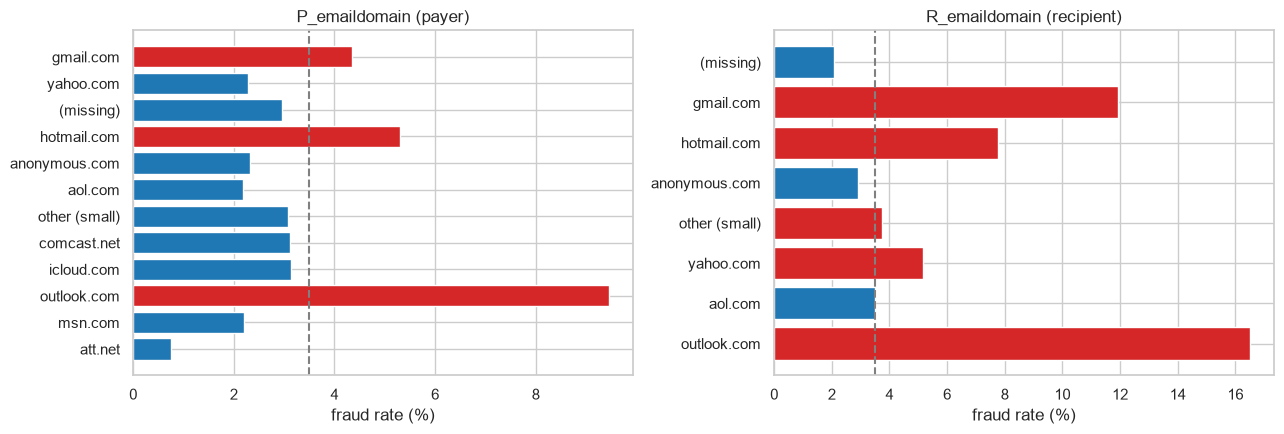

Both domains present: 21.4% of transactions. Among them: same domain fraud rate 9.65%, different domain 2.87%


In [11]:
p_tab = rate_table("P_emaildomain", min_count=2000, top=12)
r_tab = rate_table("R_emaildomain", min_count=2000, top=12)
print("Payer e-mail domain (top by volume)")
display(p_tab.style.format(FMT))
print("Recipient e-mail domain (top by volume)")
display(r_tab.style.format(FMT))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_rates(p_tab, "P_emaildomain (payer)", axes[0])
plot_rates(r_tab, "R_emaildomain (recipient)", axes[1])
save_fig(fig, "04_email_domain_rates")

both = df["P_emaildomain"].notna() & df["R_emaildomain"].notna()
same = both & (df["P_emaildomain"].astype(str) == df["R_emaildomain"].astype(str))
print(
    f"Both domains present: {both.mean():.1%} of transactions. Among them: "
    f"same domain fraud rate {df.loc[same, TARGET].mean():.2%}, "
    f"different domain {df.loc[both & ~same, TARGET].mean():.2%}"
)

### 4.4 Device, distance, hour of day

Note: the dataset's time zone is unknown, so "hour" is relative to the reference date, not local time.
It can still capture a daily cycle.

,transactions,share,fraud_rate
DeviceType,,,
(missing),"449,730",76.2%,2.10%
desktop,"85,165",14.4%,6.52%
mobile,"55,645",9.4%,10.17%


dist1 by class (only where present)


,count,mean,std,min,50%,90%,99%,max
legit,"233,514.0",117.4,370.6,0.0,8.0,255.0,"2,034.0","10,286.0"
fraud,"4,755.0",174.6,424.2,0.0,10.0,642.0,"2,132.6","4,942.0"


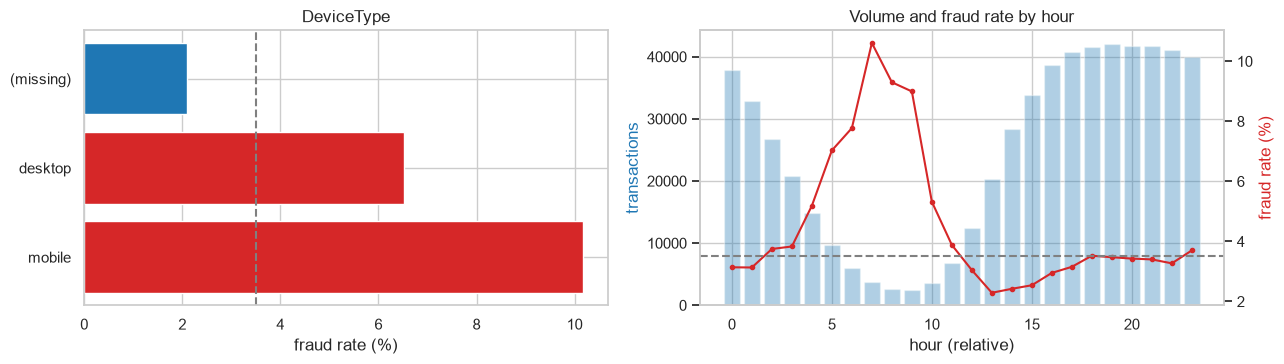

Hourly fraud rate range: 2.29% – 10.61%
Highest-risk hours: {7: 0.1061, 8: 0.093, 9: 0.09, 6: 0.0777}
Lowest-volume hours: {9: 2479, 8: 2591, 10: 3627, 7: 3704}


In [12]:
dev_tab = rate_table("DeviceType", min_count=1)
display(dev_tab.style.format(FMT))

dist = df.groupby(TARGET)["dist1"].describe(percentiles=[0.5, 0.9, 0.99])
dist.index = ["legit", "fraud"]
print("dist1 by class (only where present)")
display(dist.style.format("{:,.1f}"))

hour = df[config.DATETIME_COL].dt.hour
hourly = df.groupby(hour)[TARGET].agg(transactions="size", fraud_rate="mean")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
plot_rates(dev_tab, "DeviceType", axes[0])
ax = axes[1]
ax.bar(hourly.index, hourly["transactions"], color="tab:blue", alpha=0.35)
ax.set_xlabel("hour (relative)")
ax.set_ylabel("transactions", color="tab:blue")
ax2 = ax.twinx()
ax2.plot(hourly.index, hourly["fraud_rate"] * 100, color="tab:red", marker="o", ms=3)
ax2.axhline(OVERALL_RATE * 100, ls="--", color="grey")
ax2.set_ylabel("fraud rate (%)", color="tab:red")
ax2.grid(False)
ax.set_title("Volume and fraud rate by hour")
save_fig(fig, "04_device_and_hour")

print(
    f"Hourly fraud rate range: {hourly['fraud_rate'].min():.2%} – {hourly['fraud_rate'].max():.2%}"
)
print("Highest-risk hours:", hourly["fraud_rate"].nlargest(4).round(4).to_dict())
print("Lowest-volume hours:", hourly["transactions"].nsmallest(4).to_dict())

**Observations (section 4)**
- **Amount alone is a weak signal.** Distributions overlap heavily (median $75 fraud vs $68.5 legit). Fraud has
  a fatter middle (75th percentile $161 vs $120) but no extreme values (max $5,191 vs $31,937).
  Whole-dollar amounts are barely riskier (3.59% vs 3.41%). → Amount **relative to the card's own history**
  (L03) should be much more useful than the raw amount.
- **ProductCD is strong:** product C has 11.7% fraud vs 2.0% for W (75% of volume).
- **Card type:** credit 6.7% vs debit 2.4%. Card network matters little (Visa ≈ Mastercard ≈ 3.4%), except
  Discover at 7.7% (small volume).
- **E-mail domains:** payer outlook.com 9.5%, hotmail.com 5.3%, gmail.com 4.4%, att.net 0.7%. Recipient gmail.com
  11.9%, outlook.com 16.5%.
- **Surprise:** when both domains are present, *same* payer/recipient domain is riskier (9.7%) than *different*
  (2.9%). This is the opposite of the initial "mismatch = risk" assumption. The feature is still useful,
  but its direction and wording must follow the data, not intuition. (It may partly reflect product C.)
- **Device:** mobile 10.2%, desktop 6.5%, no device data 2.1% (mostly the identity-presence effect above).
- **Distance (`dist1`):** fraud has a longer tail (90th percentile 642 vs 255).
- **Hour of day (relative):** a **strong daily cycle**. The low-volume hours (about 5–10) have the highest fraud
  rate, up to about 10.6% around hour 7, vs about 2.3% in the busiest hours. → Hour is a useful, explainable feature.

<!-- S3 -->
## 5. Time coverage and proposed split dates

The model will be used on *future* transactions, so it must be evaluated on a later period than it was
trained on. The rule: **train ≈ 60% / validation ≈ 20% / test ≈ 20% of transactions in time
order, with a 7-day gap before validation and before test**. Cut points are rounded to whole days, so they
are easy to read and reuse in L03.

Why the gaps? Some behavioural features look back several days, and fraud labels arrive late in reality
(chargebacks). A gap stops the end of one period from leaking into the start of the next.

In [13]:
test_df = load_split("test")
DT = config.DATETIME_COL
coverage = pd.DataFrame(
    {
        "start": [df[DT].min(), test_df[DT].min()],
        "end": [df[DT].max(), test_df[DT].max()],
        "rows": [len(df), len(test_df)],
    },
    index=["Kaggle train (labelled)", "Kaggle test (no labels)"],
)
coverage["days"] = (coverage["end"] - coverage["start"]).dt.days + 1
display(coverage)
print(f"Gap between Kaggle train and test: {(test_df[DT].min() - df[DT].max()).days} days")

,start,end,rows,days
Kaggle train (labelled),2017-12-02 00:00:00,2018-06-01 23:58:51,590540,182
Kaggle test (no labels),2018-07-02 00:00:24,2018-12-31 23:59:05,506691,183


Gap between Kaggle train and test: 30 days


In [14]:
# Row-share quantiles, rounded down to midnight.
q60 = df[DT].quantile(0.60).normalize()
q80 = df[DT].quantile(0.80).normalize()
GAP = pd.Timedelta(days=7)
SPLIT = {
    "train": (df[DT].min().normalize(), q60),
    "gap_1": (q60, q60 + GAP),
    "validation": (q60 + GAP, q80),
    "gap_2": (q80, q80 + GAP),
    "test": (q80 + GAP, df[DT].max().normalize() + pd.Timedelta(days=1)),
}


def period_of(ts):
    out = pd.Series("unassigned", index=ts.index)
    for name, (a, b) in SPLIT.items():
        out[(ts >= a) & (ts < b)] = name
    return out


df["period"] = period_of(df[DT])
split_tab = df.groupby("period", sort=False)[TARGET].agg(rows="size", fraud_rate="mean")
split_tab = split_tab.loc[list(SPLIT)]
split_tab["share"] = split_tab["rows"] / len(df)
split_tab["from (incl.)"] = [SPLIT[p][0].date() for p in split_tab.index]
split_tab["to (excl.)"] = [SPLIT[p][1].date() for p in split_tab.index]
display(
    split_tab[["from (incl.)", "to (excl.)", "rows", "share", "fraud_rate"]].style.format(
        {"rows": "{:,}", "share": "{:.1%}", "fraud_rate": "{:.2%}"}
    )
)
assert (df["period"] != "unassigned").all()

,from (incl.),to (excl.),rows,share,fraud_rate
period,,,,,
train,2017-12-02,2018-03-12,"353,716",59.9%,3.38%
gap_1,2018-03-12,2018-03-19,"20,946",3.5%,3.78%
validation,2018-03-19,2018-04-21,"97,344",16.5%,3.93%
gap_2,2018-04-21,2018-04-28,"18,549",3.1%,3.44%
test,2018-04-28,2018-06-02,"99,985",16.9%,3.43%


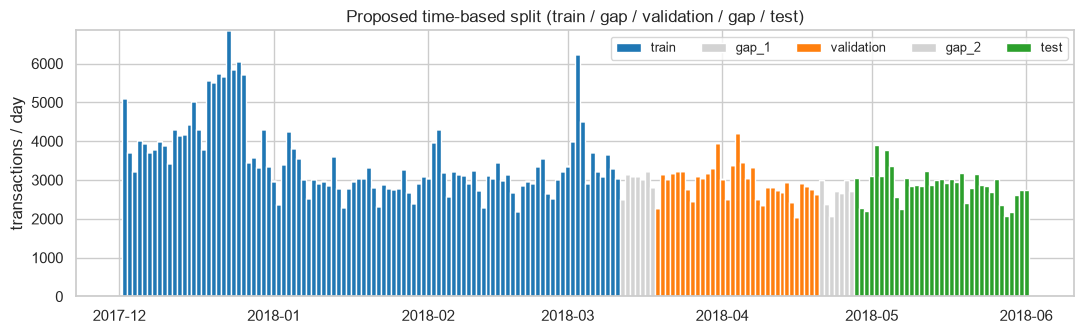

In [15]:
colors = {
    "train": "tab:blue",
    "gap_1": "lightgrey",
    "validation": "tab:orange",
    "gap_2": "lightgrey",
    "test": "tab:green",
}
daily_p = df.groupby([df[DT].dt.floor("D"), "period"]).size().unstack(fill_value=0)[list(SPLIT)]
fig, ax = plt.subplots(figsize=(11, 3.5))
bottom = np.zeros(len(daily_p))
for p in SPLIT:
    ax.bar(daily_p.index, daily_p[p], bottom=bottom, width=1.0, color=colors[p], label=p)
    bottom += daily_p[p].values
ax.set_ylabel("transactions / day")
ax.set_title("Proposed time-based split (train / gap / validation / gap / test)")
ax.legend(ncol=5, loc="upper right", fontsize=9)
save_fig(fig, "05_time_split")

**Observations (section 5)**
- Kaggle train covers **182 days (2017-12-02 → 2018-06-01)**. The unlabelled Kaggle test covers the next
  6 months (2018-07-02 → 2018-12-31), **after a ~1-month gap**. It is useful only as unlabelled "future
  traffic" for the drift demo (L12).
- **Proposed split (for L03):** train **2017-12-02 → 2018-03-11**, gap 03-12 → 03-18, validation
  **2018-03-19 → 2018-04-20**, gap 04-21 → 04-27, test **2018-04-28 → 2018-06-01**. Rows ≈ 60% / 3.5% / 16.5% /
  3.1% / 16.9%. The two gaps (~6.6% of rows) are not used for training or scoring. They can still be used
  as *history* for behavioural features, because that history is in the past.
- Fraud rate per period: train ≈ 3.4%, validation ≈ 3.9%, test ≈ 3.4%. The periods are comparable, and the
  holiday-heavy December is entirely in train.

## 6. Drift: does the data change over time?

**PSI (Population Stability Index)** compares a feature's distribution in a *reference* period with a
*current* period. Numeric features use 10 quantile bins from the reference; categorical features use the
top categories + "other"; missing values get their own bin.
Rule of thumb: **< 0.1 stable, 0.1–0.25 moderate, > 0.25 significant**.

Two comparisons:
1. **First vs last month of the labelled data** (December 2017 vs May 2018).
2. **Labelled train period vs Kaggle test period** (≈ 7 months later, no labels needed for drift).

In [16]:
def psi(ref, cur, bins=10, top_k=15, eps=1e-4):
    """Population Stability Index of `cur` against `ref` (missing values are their own bin)."""
    ref, cur = pd.Series(ref), pd.Series(cur)
    if pd.api.types.is_numeric_dtype(ref) and not isinstance(ref.dtype, pd.CategoricalDtype):
        edges = np.unique(np.nanquantile(ref.astype(float), np.linspace(0, 1, bins + 1)))
        edges[0], edges[-1] = -np.inf, np.inf

        def to_bins(s):
            b = pd.cut(s.astype(float), edges, labels=False, include_lowest=True)
            return b.fillna(-1).astype(int)

        r, c = to_bins(ref), to_bins(cur)
    else:
        top = ref.astype("object").value_counts().index[:top_k]

        def to_bins(s):
            s = s.astype("object")
            return s.where(s.isin(top), "other").where(s.notna(), "(missing)")

        r, c = to_bins(ref), to_bins(cur)
    p = r.value_counts(normalize=True)
    q = c.value_counts(normalize=True)
    p, q = p.align(q, fill_value=0)
    p, q = p.clip(lower=eps), q.clip(lower=eps)
    return float(((q - p) * np.log(q / p)).sum())


def severity(v):
    return "stable" if v < 0.1 else ("moderate" if v < 0.25 else "significant")


DRIFT_COLS = [
    "TransactionAmt",
    "ProductCD",
    "card4",
    "card6",
    "P_emaildomain",
    "R_emaildomain",
    "DeviceType",
    "DeviceInfo",
    "id_31",
    "dist1",
    "C1",
    "C13",
    "D1",
    "D15",
    "V258",
    "addr1",
]
first_month = df[df[DT] < "2018-01-01"]
last_month = df[df[DT] >= "2018-05-01"]
rows = []
for col in DRIFT_COLS:
    v1 = psi(first_month[col], last_month[col])
    v2 = psi(df[col], test_df[col])
    rows.append(
        {
            "feature": col,
            "PSI Dec→May": v1,
            "Dec→May": severity(v1),
            "PSI train→Kaggle test": v2,
            "train→test": severity(v2),
        }
    )
drift = (
    pd.DataFrame(rows).set_index("feature").sort_values("PSI train→Kaggle test", ascending=False)
)
display(drift.style.format({"PSI Dec→May": "{:.3f}", "PSI train→Kaggle test": "{:.3f}"}))

,PSI Dec→May,Dec→May,PSI train→Kaggle test,train→test
feature,,,,
id_31,1.353,significant,0.936,significant
D15,0.450,significant,0.339,significant
C13,0.119,moderate,0.043,stable
DeviceInfo,0.302,significant,0.022,stable
D1,0.125,moderate,0.021,stable
DeviceType,0.232,moderate,0.009,stable
R_emaildomain,0.171,moderate,0.009,stable
card4,0.070,stable,0.007,stable
dist1,0.100,stable,0.007,stable


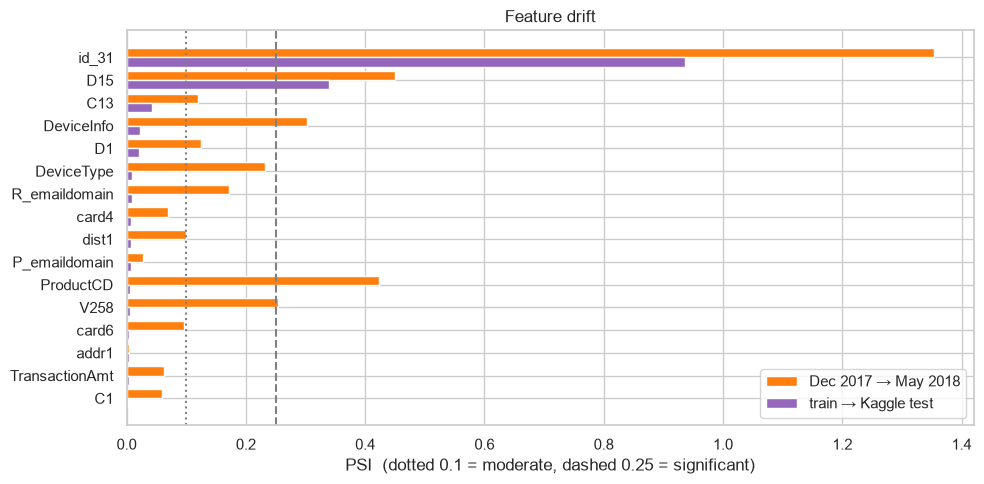

Top id_31 (browser) values, train vs Kaggle test:


,train,Kaggle test
id_31,,
chrome 63.0,15.7%,–
mobile safari 11.0,9.6%,7.5%
mobile safari generic,8.2%,–
ie 11.0 for desktop,6.4%,–
safari generic,5.8%,–
chrome 62.0,5.1%,–
chrome 70.0,–,11.8%
mobile safari 12.0,–,9.6%
chrome 71.0,–,6.9%


In [17]:
fig, ax = plt.subplots(figsize=(10, 5))
y = np.arange(len(drift))
ax.barh(y - 0.2, drift["PSI Dec→May"], height=0.4, label="Dec 2017 → May 2018", color="tab:orange")
ax.barh(
    y + 0.2,
    drift["PSI train→Kaggle test"],
    height=0.4,
    label="train → Kaggle test",
    color="tab:purple",
)
ax.set_yticks(y, drift.index)
ax.invert_yaxis()
for x, ls in [(0.1, ":"), (0.25, "--")]:
    ax.axvline(x, color="grey", ls=ls)
ax.set_xlabel("PSI  (dotted 0.1 = moderate, dashed 0.25 = significant)")
ax.set_title("Feature drift")
ax.legend(loc="lower right")
save_fig(fig, "06_drift_psi")

print("Top id_31 (browser) values, train vs Kaggle test:")
display(
    pd.concat(
        {
            "train": df["id_31"].value_counts(normalize=True).head(6),
            "Kaggle test": test_df["id_31"].value_counts(normalize=True).head(6),
        },
        axis=1,
    ).style.format("{:.1%}", na_rep="–")
)

**Observations (section 6)**
- **Browser version (`id_31`) drifts the most** (PSI 1.35 Dec→May, 0.94 train→Kaggle test). Versions simply
  move on: "chrome 63.0" is 15.7% of train and absent from the test period, where "chrome 70/71" dominate.
  → Do **not** use raw browser versions. Use the browser *family* (chrome / safari / ie / …), or drop the column.
  This is also the clearest drift story for the demo (L12).
- **Time-delta columns drift:** `D15` is significant in both comparisons and `D1` is moderate. The `D` columns
  count days since past events, so their values grow as the data moves forward in time.
  → In L03, normalise them as `day − D` (e.g. the card's "first-seen day"), which is stable over time.
- **Seasonality inside the labelled data:** `ProductCD` (0.42), `DeviceInfo` (0.30), `V258` (0.25),
  `DeviceType` and `R_emaildomain` change between December and May, but are stable from train to the Kaggle
  test period. The holiday month has a different product mix. → December being entirely in train is fine,
  but per-week metrics (L05) should show whether the model degrades over time.
- **Stable:** amount, card network/type, payer e-mail, `addr1`, `C1`, `dist1`.

## 7. Pseudo customer key (`uid`)

The dataset has no customer ID. A common reconstruction used in the competition:
`uid = card1 + addr1 + (day − D1)`. `card1` identifies the card, `addr1` the billing region, and
`day − D1` estimates the card's *first-seen day*, since `D1` looks like "days since the card was first seen".
If this works, the same uid should group the transactions of one customer.

In [18]:
day = (df[config.TIME_COL] // 86_400).astype(int)
df["uid"] = (
    df["card1"].astype(str) + "_" + df["addr1"].astype(str) + "_" + (day - df["D1"]).astype(str)
)
# pandas 3: a missing addr1 / D1 stays missing after astype(str), so those rows get uid = NaN.
print(f"rows without a uid (addr1 or D1 missing): {df['uid'].isna().mean():.1%}")
tx_per_uid = df["uid"].value_counts()
print(f"distinct uids: {len(tx_per_uid):,}  (vs {df['card1'].nunique():,} distinct card1 values)")
print(
    f"uids with 1 transaction: {(tx_per_uid == 1).mean():.1%}; median {tx_per_uid.median():.0f}, "
    f"p90 {tx_per_uid.quantile(0.9):.0f}, p99 {tx_per_uid.quantile(0.99):.0f}, max {tx_per_uid.max():,}"
)
print(
    f"transactions belonging to a uid with ≥ 2 transactions: {(df['uid'].map(tx_per_uid) >= 2).mean():.1%}"
)
print("largest uids:", tx_per_uid.head(3).to_dict())

# Does the uid look like one customer? Its email domain / device should rarely change.
multi = df[df["uid"].map(tx_per_uid) >= 2]
consistency = {
    col: (multi.groupby("uid", observed=True)[col].nunique(dropna=True) <= 1).mean()
    for col in ["P_emaildomain", "card4", "card6", "DeviceType"]
}
print(
    "Share of multi-transaction uids with a single value of:",
    {k: f"{v:.1%}" for k, v in consistency.items()},
)

rows without a uid (addr1 or D1 missing): 11.3%
distinct uids: 199,070  (vs 13,553 distinct card1 values)
uids with 1 transaction: 58.0%; median 1, p90 6, p99 19, max 1,414


transactions belonging to a uid with ≥ 2 transactions: 69.1%
largest uids: {'15775_330.0_129.0': 1414, '9500_126.0_-85.0': 446, '8900_231.0_-60.0': 232}


Share of multi-transaction uids with a single value of: {'P_emaildomain': '73.9%', 'card4': '100.0%', 'card6': '99.8%', 'DeviceType': '96.0%'}


## 8. Leakage checks

Leakage means information the model would *not* have at prediction time sneaks into training or
evaluation and makes results look better than they will be in production. Checks:
1. duplicate IDs;
2. any single column that almost perfectly predicts fraud on its own (univariate ROC-AUC);
3. **label propagation inside a uid**: the competition host said that once a card/account is reported
   as fraud, its *later* transactions were also labelled fraud;
4. **entity overlap**: how many validation/test transactions belong to uids already seen in train.

In [19]:
print(
    "Duplicate TransactionID (train, Kaggle test):",
    df[config.ID_COL].duplicated().sum(),
    test_df[config.ID_COL].duplicated().sum(),
)

# Univariate ROC-AUC for every numeric column (missing -> lowest value), via ranks (Mann-Whitney).
from scipy.stats import rankdata

y = df[TARGET].to_numpy()
n_pos, n_neg = y.sum(), (1 - y).sum()
skip = {TARGET, config.ID_COL, config.TIME_COL}
aucs = {}
for col in df.columns:
    if col in skip or not pd.api.types.is_numeric_dtype(df[col]):
        continue
    x = df[col].to_numpy(dtype="float64")
    x = np.where(np.isnan(x), np.nanmin(x) - 1 if np.isfinite(np.nanmin(x)) else -1, x)
    r = rankdata(x)
    auc = (r[y == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)
    aucs[col] = max(auc, 1 - auc)
auc_s = pd.Series(aucs, name="univariate_auc").sort_values(ascending=False)
print(
    f"Numeric columns scanned: {len(auc_s)}; max univariate AUC = {auc_s.iloc[0]:.3f} ({auc_s.index[0]})"
)
print(f"Columns with AUC > 0.95 (suspicious): {(auc_s > 0.95).sum()}")
display(auc_s.head(10).to_frame().style.format("{:.3f}"))

# Categorical: any big category that is (almost) always fraud?
cat_rows = []
for col in df.select_dtypes("category").columns:
    t = df.groupby(df[col].astype("object"), observed=True)[TARGET].agg(["size", "mean"])
    t = t[t["size"] >= 200]
    if len(t):
        cat_rows.append(
            {
                "column": col,
                "category": t["mean"].idxmax(),
                "rows": int(t.loc[t["mean"].idxmax(), "size"]),
                "fraud_rate": t["mean"].max(),
            }
        )
cat_top = (
    pd.DataFrame(cat_rows).sort_values("fraud_rate", ascending=False).head(6).set_index("column")
)
print("Riskiest category per column (categories with ≥ 200 rows):")
display(cat_top.style.format({"fraud_rate": "{:.1%}", "rows": "{:,}"}))

Duplicate TransactionID (train, Kaggle test): 0 0


Numeric columns scanned: 400; max univariate AUC = 0.688 (C4)
Columns with AUC > 0.95 (suspicious): 0


,univariate_auc
C4,0.688
C8,0.683
V201,0.679
C10,0.678
V199,0.678
V200,0.677
V168,0.677
V171,0.676
V204,0.676
V203,0.676


Riskiest category per column (categories with ≥ 200 rows):


,category,rows,fraud_rate
column,,,
DeviceInfo,SM-A300H Build/LRX22G,203,83.3%
id_33,855x480,250,38.0%
id_30,Android 5.1.1,350,28.9%
id_31,android webview 4.0,285,24.2%
P_emaildomain,mail.com,559,19.0%
R_emaildomain,outlook.com,"2,507",16.5%


In [20]:
# 3. Label propagation: fraud rate of a transaction given the label of the previous transaction
#    of the same uid (and, for comparison, of the same card1).
d = df.sort_values(config.TIME_COL)
rows = []
for key in ["uid", "card1"]:
    prev = d.groupby(key, observed=True)[TARGET].shift()
    rows.append(
        {
            "key": key,
            "P(fraud | previous was fraud)": d.loc[prev == 1, TARGET].mean(),
            "P(fraud | previous was legit)": d.loc[prev == 0, TARGET].mean(),
            "transactions after a fraud": int((prev == 1).sum()),
        }
    )
prop = pd.DataFrame(rows).set_index("key")
display(
    prop.style.format(
        {
            "P(fraud | previous was fraud)": "{:.1%}",
            "P(fraud | previous was legit)": "{:.2%}",
            "transactions after a fraud": "{:,}",
        }
    )
)

g = df.groupby("uid")[TARGET].agg(["size", "sum"])
fraud_uids = g[(g["size"] >= 2) & (g["sum"] > 0)]
print(
    f"uids with ≥ 2 transactions and at least one fraud: {len(fraud_uids):,}; "
    f"of these, {(fraud_uids['sum'] == fraud_uids['size']).mean():.1%} are fraud on EVERY transaction"
)

,P(fraud | previous was fraud),P(fraud | previous was legit),transactions after a fraud
key,,,
uid,87.2%,0.36%,"8,847"
card1,38.5%,2.25%,"20,229"


uids with ≥ 2 transactions and at least one fraud: 2,716; of these, 54.6% are fraud on EVERY transaction


In [21]:
# 4. Entity overlap between periods. Rows without a uid are counted separately
#    (NaN must never match NaN when comparing sets).
train_part = df[df["period"] == "train"]
train_uids = set(train_part["uid"].dropna())
train_fraud_uids = set(train_part.loc[train_part[TARGET] == 1, "uid"].dropna())
rows = []
for p in ["validation", "test"]:
    part = df[df["period"] == p]
    has_uid = part["uid"].notna()
    seen = has_uid & part["uid"].isin(train_uids)
    seen_fraud = has_uid & part["uid"].isin(train_fraud_uids)
    rows.append(
        {
            "period": p,
            "rows": len(part),
            "no uid": (~has_uid).mean(),
            "uid seen in train": seen.mean(),
            "fraud rate (seen uid)": part.loc[seen, TARGET].mean(),
            "fraud rate (new uid)": part.loc[has_uid & ~seen, TARGET].mean(),
            "uid had fraud in train": seen_fraud.mean(),
            "fraud rate (uid had fraud in train)": part.loc[seen_fraud, TARGET].mean(),
        }
    )
overlap = pd.DataFrame(rows).set_index("period")
print(
    "rows whose uid had a fraud in train:",
    {p: int(r["uid had fraud in train"] * r["rows"]) for p, r in overlap.iterrows()},
)
display(
    overlap.style.format({"rows": "{:,}", **{c: "{:.1%}" for c in overlap.columns if c != "rows"}})
)

rows whose uid had a fraud in train: {'validation': 965, 'test': 663}


,rows,no uid,uid seen in train,fraud rate (seen uid),fraud rate (new uid),uid had fraud in train,fraud rate (uid had fraud in train)
period,,,,,,,
validation,"97,344",13.1%,39.4%,1.6%,3.4%,1.0%,60.5%
test,"99,985",10.4%,29.4%,1.3%,2.7%,0.7%,52.2%


**Observations (sections 7–8)**
- **The `uid` reconstruction works reasonably well:** 199,070 uids (vs 13,553 `card1` values), 58% with a
  single transaction, p99 = 19 transactions. Inside a multi-transaction uid the card network is always the
  same (100%), the card type almost always (99.8%), and the device type mostly (96%). The payer e-mail
  matches less often (73.9%), so a uid is a *good approximation* of a customer, not an exact one.
  11.3% of rows have no uid (missing `addr1` or `D1`), and those rows are riskier (see §3).
  A few uids are huge (max 1,414 transactions), probably shared or default card details rather than one person.
- **No single-column leak:** no duplicate IDs; the best single numeric column (`C4`) only reaches
  ROC-AUC 0.69; no column above 0.95.
- **Rare categories can be "memorised":** e.g. one `DeviceInfo` model has 83% fraud over 203 rows (probably
  one fraud ring). → L03: frequency-encode high-cardinality columns and group rare values, so the model
  doesn't learn individual IDs.
- **⚠ Label propagation is confirmed and strong:** after a fraud, the *same uid's* next transaction is fraud
  **87.2%** of the time (vs 0.36% after a legit one). 54.6% of uids with a fraud are fraud on *every*
  transaction. For comparison, by `card1` alone it is 38.5% vs 2.25%.
- **Entity overlap:** 39% (validation) / 29% (test) of rows belong to uids already seen in train. Only
  **1.0% / 0.7%** of rows belong to uids that had a *fraud* in train, but those rows are **60.5% / 52.2% fraud**.
  In test that is ~350 frauds, roughly **10% of all test frauds**.
- → **Implications (must-follow rules for L03–L05):**
  1. **Never use past labels of the same uid/card as features** (no "previous fraud" flag, no target
     encoding by uid/card). In production, labels arrive weeks later (chargebacks). Using them without a
     realistic delay would be leakage. The lean MVP does not use label-based features at all.
  2. **Never use `uid` (or `TransactionID`) directly as a model feature.** Only aggregates computed from
     *past* transactions (counts, amounts, novelty) are allowed.
  3. **Report test metrics twice: all rows, and rows whose uid had no fraud in train.** The model can
     partly recognise "known fraudulent customers" through `card1`/`addr1`/`D`-features, and in reality
     those cards would already be blocked. The second number is the honest one for new fraud.

## 9. Conclusion and implications

**Dataset decision: IEEE-CIS is confirmed** (no PaySim fallback). The data is large enough, has no
single-column leak, shows real drift over time, and has enough readable or easily engineered signals for
explanations analysts can understand.

**For L03 (features + split)**
- Time split: train 2017-12-02 → 2018-03-11 · gap · validation 2018-03-19 → 2018-04-20 · gap · test 2018-04-28 → 2018-06-01.
- Keep NaN (trees handle it); add flags `has_identity`, `has_uid` / `addr1_missing`.
- Engineered, readable features first: amount vs the card's own history (raw amount is weak), hour of day,
  `ProductCD`, card type, device type, e-mail domains (+ same-domain flag, risk direction from data),
  24 h velocity and novelty per uid computed **from past transactions only**.
- Normalise `D` columns as `day − D`; browser family instead of `id_31` version; frequency-encode and group
  rare values of high-cardinality columns (`card1`, `DeviceInfo`, e-mail domains).
- **Forbidden:** past labels of the same uid/card, and `uid` / `TransactionID` as raw features.

**For L04–L05 (evaluation)**
- Primary metric PR-AUC, plus recall at precision and precision@150/day. Fraud rate per period is
  3.4% / 3.9% / 3.4%, so absolute numbers vary by period.
- Report test metrics **overall and excluding uids that had a fraud in train** (~10% of test frauds come
  from such uids).
- Report per-week metrics on test to show stability under drift.

**For L12 (monitoring demo)**
- Browser version (`id_31`) and `D15` drift strongly into the Kaggle test period. They make a clear,
  explainable drift example. Amount and card features stay stable.